# Exercise 34 – Learning an energy landscape with descriptors

**Week 6 · Regression**

One atom (blue) moves along the $x$-axis through a ring of six fixed atoms.
From the energies at only eight positions we want to predict the energy
everywhere along the path, with Gaussian-kernel ridge regression on three
different inputs:

1. the raw coordinate $x$,
2. the pair-distance histogram of the whole system,
3. the Coulomb-matrix spectrum.

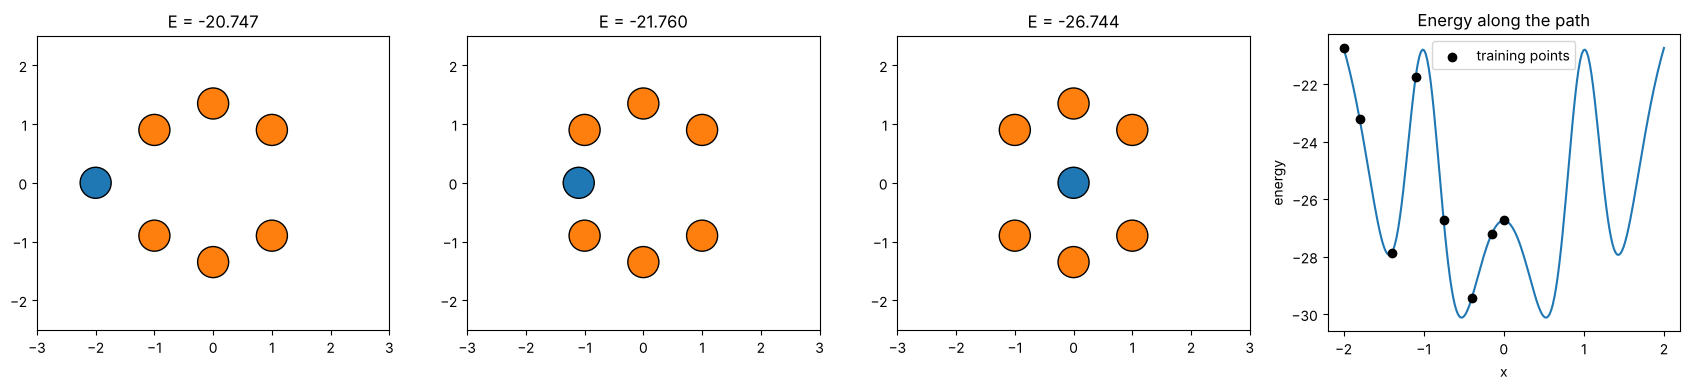

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from comphy.atoms import Cluster, LennardJones
from comphy.descriptors import CoulombMatrixSpectrum, PairDistances
from comphy.regression import KernelRidge, gaussian_kernel

calc = LennardJones()
ring = np.array([[-1, 0.9], [0, 1.35], [1, 0.9], [1, -0.9], [0, -1.35], [-1, -0.9]])


def system(x):
    return np.vstack([[x, 0.0], ring])


x_train = np.array([-2, -1.8, -1.4, -1.1, -0.75, -0.4, -0.15, 0.0])
E_train = np.array([calc.energy(system(x)) for x in x_train])
xs = np.linspace(-2, 2, 200)
E_true = np.array([calc.energy(system(x)) for x in xs])

fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, x in zip(axes[:3], [-2, -1.1, 0.0]):
    Cluster(calc, system(x), static=[False] + [True] * 6).draw(ax, size=500)
    ax.set(xlim=(-3, 3), ylim=(-2.5, 2.5))
axes[3].plot(xs, E_true)
axes[3].scatter(x_train, E_train, color="black", zorder=3, label="training points")
axes[3].set(xlabel="x", ylabel="energy", title="Energy along the path")
axes[3].legend()
fig.tight_layout()
plt.show()

All training points lie on the left half. Because of the mirror symmetry the
right half has the same energies, but a model has to *know* that to predict it.

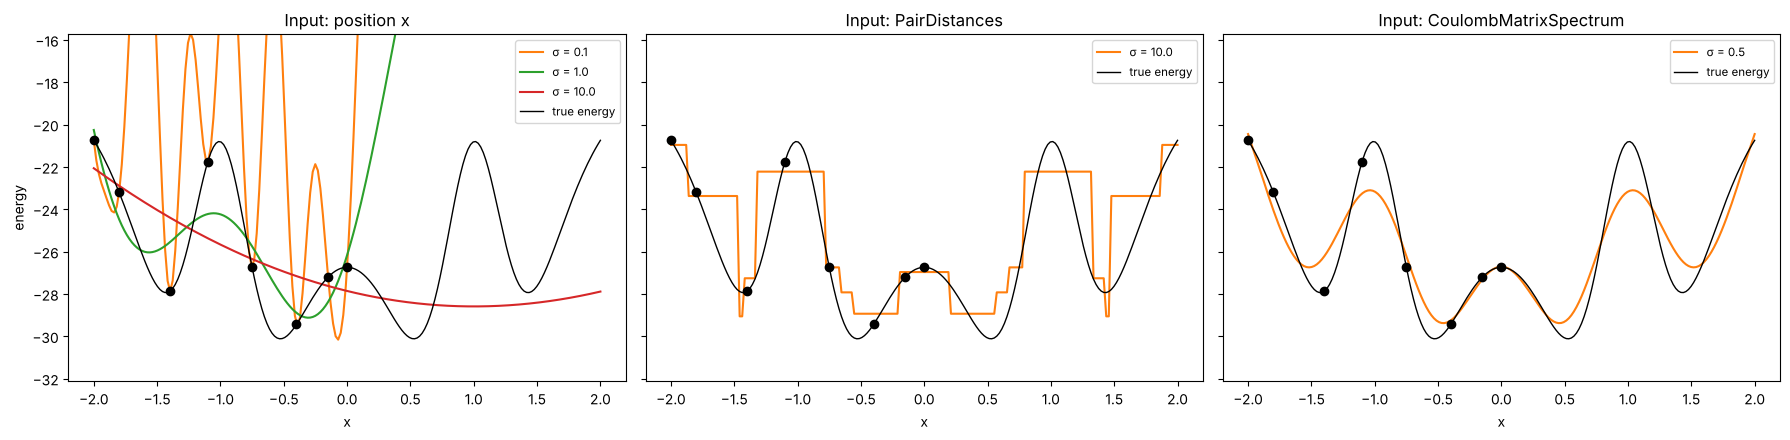

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)

for i, s in enumerate([0.1, 1.0, 10.0]):
    model = KernelRidge(gaussian_kernel(s), 1e-4).fit(x_train, E_train)
    axes[0].plot(xs, model.predict(xs), color=f"C{i + 1}", label=f"σ = {s}")
axes[0].set_title("Input: position x")

for ax, descriptor, s in [(axes[1], PairDistances(), 10.0), (axes[2], CoulombMatrixSpectrum(), 0.5)]:
    X_train = np.array([descriptor(system(x)) for x in x_train])
    X_all = np.array([descriptor(system(x)) for x in xs])
    model = KernelRidge(gaussian_kernel(s), 0.01).fit(X_train, E_train)
    ax.plot(xs, model.predict(X_all), color="C1", label=f"σ = {s}")
    ax.set_title(f"Input: {descriptor.name}")

for ax in axes:
    ax.plot(xs, E_true, color="black", lw=1, label="true energy")
    ax.scatter(x_train, E_train, color="black", zorder=3)
    ax.set(xlabel="x", ylim=(E_true.min() - 2, E_train.max() + 5))
    ax.legend(fontsize="small")
axes[0].set_ylabel("energy")
fig.tight_layout()
plt.show()

Using $x$ directly, the model knows nothing about the right half and the
prediction there depends entirely on the kernel width. The descriptors are
invariant to the mirror symmetry, so a configuration at $+x$ looks identical
to one at $-x$ and the energies on the right are predicted correctly for
free – a good descriptor builds the physics into the input. The pair-distance
histogram changes in discrete jumps when a distance crosses a bin edge, so
its prediction is a staircase; the continuous Coulomb-matrix spectrum gives a
smooth curve.